# 02 — Fit an H3 resolution to each dataset

The rule picks the coarsest H3 resolution whose average cell is no larger than the dataset's pixel, measured at the AOI.
The field resolution must then be at least as fine as every dataset's fitted resolution.

In [0]:
%run ./config_nb

geobrix 0.6.0: one wheel per runtime (+env5 / +env6); SQL functions register through databricks.labs.gbx.register(spark); the Python API is rasterx / gridx / vectorx. See https://databrickslabs.github.io/geobrix/docs/migration-0-6
geobrix: JVM level unavailable: Spark Connect session (Serverless); using the Python level (48 functions)
geobrix: SQL expression level unavailable: 5 functions (gbx_bng_cellarea, gbx_bng_eastnorthasbng, gbx_quadbin_distance, ...) need a SQL function wrapper, and SQL functions are unavailable here; using the Python level


... EARTHDATA_TOKEN loaded from geospatial_docs.vapor_eyes.earthdata_token


True

DataFrame[]

H3PX_DIR = /Volumes/geospatial_docs/h3_pixels_crop_yield/data/h3-pixels-crop-yield


... view helpers: show_cells, show_tile (gated by INTERACTIVE_PLOTS)


In [0]:
DATASETS = [a[0] for a in ATTRIBUTES] + (["hls_l30", "hls_s30"] if EARTHDATA_READY else [])
samples = functools.reduce(DataFrame.unionByName, [dataset_tiles(d).limit(1) for d in DATASETS])
fit = samples.selectExpr("dataset", f"gbx_rst_h3_fitresolution(tile, '{RES_RULE}') AS attr_h3_res", "tile").collect()

## The pixel and the cell beside it

`gbx_rst_h3_fitresolution` returns only the resolution.
The notebook measures the centre pixel with the same GeoBrix code the function uses, and the local cell at the fitted resolution with built-ins.
Each finer H3 resolution has cells about 7 times smaller, so a fitted cell is between 1 and about 7 times smaller than its pixel.
The rule uses the average cell area, so the check allows a local cell up to 5% larger than the pixel.

In [0]:
rows = []
for r in fit:
    area, lon, lat = centre_pixel(r["tile"]["raster"])
    rows.append((r["dataset"], float(area), int(r["attr_h3_res"]), lon, lat))
spark.createDataFrame(rows, "dataset string, pixel_area_m2 double, attr_h3_res int, lon double, lat double") \
    .createOrReplaceTempView("fit_rows")
res_df = spark.sql(f"""
  SELECT dataset, pixel_area_m2, attr_h3_res,
         st_area(st_transform(st_setsrid(st_geomfromwkb(h3_boundaryaswkb(
             h3_pointash3(concat('POINT (', lon, ' ', lat, ')'), attr_h3_res))), 4326), 5070)) AS cell_area_m2,
         '{RES_RULE}' AS rule
  FROM fit_rows""")
dataset_resolutions = _persist(res_df, "dataset_resolutions", rewrite=True)
display(dataset_resolutions.orderBy("attr_h3_res"))

... wrote table dataset_resolutions (7 rows)


dataset,pixel_area_m2,attr_h3_res,cell_area_m2,rule
sfsm_inst,143649889.10967255,6,35579399.39800282,not_larger
gws_inst,143649889.10967255,6,35579399.39800282,not_larger
gridmet,15970387.301803589,7,5077797.126991821,not_larger
stage4,18177730.12781906,7,5077094.466548746,not_larger
normals,15969350.207054138,7,5077797.126991821,not_larger
hls_l30,900.5128756589256,12,301.61424955453083,not_larger
hls_s30,900.5128756589256,12,301.61424955453083,not_larger


In [0]:
got = {r["dataset"]: r for r in dataset_resolutions.collect()}
assert FIELD_H3_RES >= max(r["attr_h3_res"] for r in got.values()), "the field resolution must be at least as fine"
# The rule compares the pixel with the H3 AVERAGE cell area; the local cell can be a few percent larger (5% tolerance).
small = {d: round(r["pixel_area_m2"] / r["cell_area_m2"], 3) for d, r in got.items()}
print("pixel area / local cell area:", small)
assert all(r["pixel_area_m2"] >= 0.95 * r["cell_area_m2"] for r in got.values()), f"a fitted cell exceeds its pixel: {small}"
if RES_RULE == "not_larger" and not FULL_AOI:
    want = {"stage4": 7, "normals": 7, "nclimgrid": 7, "gridmet": 7, "gws_inst": 6, "sfsm_inst": 6, "hls_l30": 12,
            "hls_s30": 12}
    assert {d: got[d]["attr_h3_res"] for d in got if d in want} == {d: want[d] for d in got if d in want}
assert got["stage4"]["attr_h3_res"] == got["normals"]["attr_h3_res"], "the precipitation anomaly joins on one resolution"

pixel area / local cell area: {'stage4': 3.58, 'normals': 3.145, 'gridmet': 3.145, 'gws_inst': 4.037, 'sfsm_inst': 4.037, 'hls_l30': 2.986, 'hls_s30': 2.986}


## Payoff

Each dataset's pixel against its fitted cell: every fitted cell is 3 to 4 times smaller than its pixel, and the next coarser resolution would be larger than the pixel.

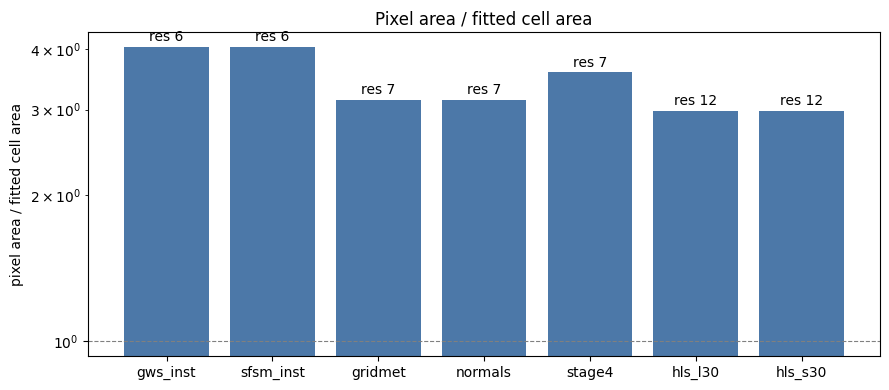

In [0]:
import matplotlib.pyplot as plt

pdf = dataset_resolutions.orderBy("attr_h3_res", "dataset").toPandas()
ratio = pdf["pixel_area_m2"] / pdf["cell_area_m2"]
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(pdf["dataset"], ratio, color="#4C78A8")
ax.bar_label(bars, labels=[f"res {r}" for r in pdf["attr_h3_res"]], padding=2)
ax.axhline(1.0, color="grey", linewidth=0.8, linestyle="--")  # a cell as large as the pixel
ax.set_yscale("log")
ax.set_ylabel("pixel area / fitted cell area")
ax.set_title("Pixel area / fitted cell area")
plt.tight_layout()
plt.show()